# <center> **Домашнее задание: NumPy** </center>
### <center> *Средиземье в массивах* </center>

*Фамилия Имя:* Великонивцев Денис

---

## Как устроено это ДЗ

- У каждого из вас будут **свои** случайные числа при одинаковой логике решения (см. блок про персональный ключ ниже).
- Внутри каждой функции-квеста названия переменных, порядок действий и стиль — полностью на ваше усмотрение. Фиксировано только имя самой функции (не переименовывайте её).
- **Докстринг — тоже часть задания**: замените заглушку `Допишите docstring сами` на своё короткое (1-2 предложения) описание того, что делает функция.
- Часть заданий заканчивается коротким текстовым ответом в отдельной markdown-ячейке под кодом — это тоже часть оценки.
- **Перед сдачей обязательно** `Kernel → Restart & Run All`. Ноутбук без сохранённого вывода (графиков и print'ов) считается невыполненным.
- Там, где явно сказано "без циклов" — используются только векторизованные операции `numpy`.

## Баллы

| Квест | Тема | Баллы |
|---|---|---|
| 1 | Свиток судьбы | 10 |
| 2 | Свет и тень | 15 |
| 3 | Совет Элронда (линейная система) | 20 |
| 4 | Оси и масштабы | 19 |
| 5 | Уникальное и порядок | 19 |
| 6 | Сила векторизации | 23 |
| 7 | Палантир видений | 10 |
| 8 | Три летописи (concatenate / stack) | 10 |
| **Итого** | | **126** |


## 🔑 Ваш персональный ключ

Впишите своё ФИО в переменную `STUDENT_ID` ниже. От неё зависит `seed` для генератора случайных чисел.

**Дальше по ноутбуку используйте только `rng`**, а не `np.random` напрямую — иначе персонализация не сработает.


In [2]:
import numpy as np
import hashlib

STUDENT_ID = "Velikonivtsev_Denis"  # например: "Ivanova_Maria"

assert STUDENT_ID != "ВПИШИТЕ_ФАМИЛИЮ_ИЛИ_ЛОГИН"

seed = int(hashlib.sha256(STUDENT_ID.encode()).hexdigest(), 16) % (2**32)
rng = np.random.default_rng(seed)

print(f"Студент: {STUDENT_ID}")
print(f"Ваш персональный seed: {seed}")

Студент: Velikonivtsev_Denis
Ваш персональный seed: 968111692


## Квест 1. Свиток Судьбы (10 баллов)

<center>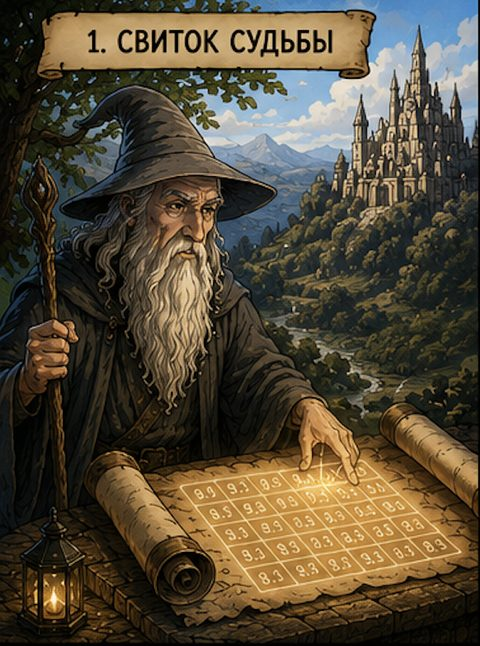</center>

В древнем свитке записана судьба Средиземья двадцатью числами.

1. Создайте массив из **20** случайных целых чисел от 0 до 100 (`rng.integers`). **(2 балла)**
2. Посчитайте и выведите на экран в форматированном виде: среднее, минимум, максимум, индекс минимального элемента. **(2 балла за каждое значение)**


In [3]:
def scroll_of_fate():
    '''
    Наш свиток, к сожалению, был утерян. Нам предстоит сложная задача по созданию
    нового списка с новой судьбой Средиземья) 
    Создаем массив из двадцати "случайных" чисел от 0 до 100. 
    Печатаем: среднее значение, минимум, максимум, индекс минимального элемента. 
    '''
    random_numbers = rng.integers(0, 101, size = 20)
    
    avg = np.mean(random_numbers)
    minimum = np.min(random_numbers)
    maximum = np.max(random_numbers)
    ind_of_minimum = np.argmin(random_numbers)
    
    print(f"Среднее значение: {avg}")
    print(f"Минимальное значение: {minimum}")
    print(f"Максимальное значение: {maximum}")
    print(f"Индекс минимального элемента: {ind_of_minimum}")

scroll_of_fate()



Среднее значение: 44.2
Минимальное значение: 3
Максимальное значение: 100
Индекс минимального элемента: 15


## Квест 2. Свет и Тень (15 баллов)

<center>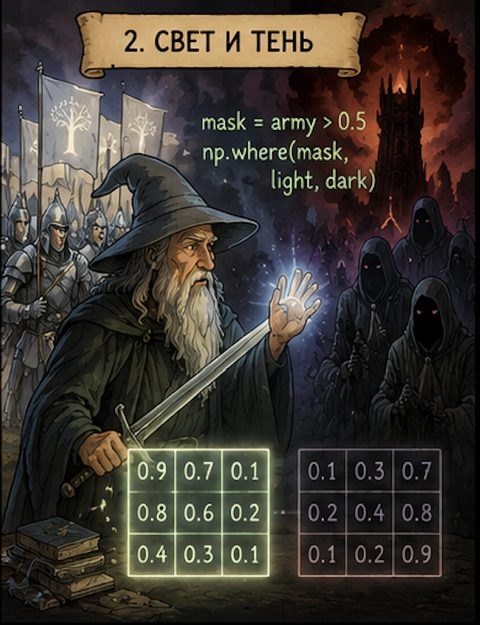</center>

Армия Света и Армия Тени сходятся в числах. Их силы меняются от хода к ходу, а исход битвы зависит от умения читать знаки.

1. Сформируйте Армию Света — массив из **9** последовательных чётных чисел. Первое число должно зависеть от персонального генератора случайных чисел и также быть чётным. **(3 балла)**
2. Сформируйте Армию Тени — массив из **9** случайных целых чисел от 5 до 60. **(2 балла)**
3. Для каждого хода битвы найдите силу столкновения: сложите силы соответствующих воинов Света и Тени, затем возведите полученный результат в квадрат. Выведите получившийся массив. **(2 балла)**
4. Найдите воинов Света, стоящих на позициях, где воин Тени сильнее 20, но его сила не делится на 4 без остатка. Выведите найденных воинов Света и количество таких позиций. **(4 балла)**
5. Создайте массив исходов битвы: на каждой позиции запишите `1`, если сила Света больше силы Тени, `-1`, если сила Тени больше силы Света, и `0`, если силы равны. Выведите массив исходов и число побед Армии Света. **(4 балла)**


In [4]:
def light_and_shadow():
    '''
    Данная функция формирует армию Света и армию Тени. Функция исследует 
    каждую армию: считает общую силу двух армий, сравнивает две армии 
    и поддсчитывает исходы битв)
    '''

    start = rng.integers(1, 26)
    army_light = np.arange(2*start, 2*start + 9*2, 2)
    print(f"Армия Света: {army_light}")
    army_shadow = rng.integers(5, 61, size = 9)
    print(f"Армия Тени: {army_shadow}")
    batle = (army_light + army_shadow) ** 2
    
    print(f"После битвы получаем значения: {batle}")
    
    found_army = army_light[(army_shadow > 20) & (army_shadow % 4 != 0)]
    len_found_army = len(found_army)
    print(f"Найденные войны света: {found_army}, а длина найденной армии: {len_found_army}")
    
    outcome_of_the_battle = (army_light > army_shadow) + (-1 * (army_light < army_shadow))
    count_of_victories = (army_light > army_shadow).sum()
    print(f"Исход битвы: {outcome_of_the_battle}, количество побед Армии Света {count_of_victories}")

light_and_shadow()

Армия Света: [32 34 36 38 40 42 44 46 48]
Армия Тени: [41 14 35 56 47 10 41 49 54]
После битвы получаем значения: [ 5329  2304  5041  8836  7569  2704  7225  9025 10404]
Найденные войны света: [32 36 40 44 46 48], а длина найденной армии: 6
Исход битвы: [-1  1  1 -1 -1  1  1 -1 -1], количество побед Армии Света 4


## Квест 3. Совет Элронда: линейная система (20 баллов)

<center>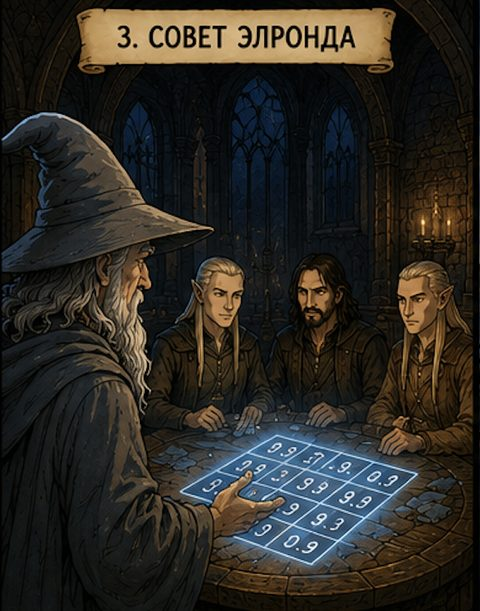</center>

*разберитесь по документации `numpy.linalg` & поспрашивайте ИИ о невязках и устойчивости в данных системах.*

> - Система `Cx = b` решается через `np.linalg.solve(C, b)`
> - Если у `C` нет обратной матрицы (определитель равен 0 — матрица **вырождена**), `numpy` бросит `LinAlgError`

Совет должен предсказать значения трёх неизвестных по результатам трёх наблюдений. Однако древние записи могут оказаться противоречивыми, поэтому необходимо не только найти решение, но и проверить его надёжность.

1. Сформируйте случайный вектор правой части размерности 3 и случайную квадратную матрицу коэффициентов размерности 3×3. Используйте персональный генератор `rng`. Все значения — от −10 до 10. **(2 балла)**
2. Проверьте, что матрица коэффициентов допускает единственное решение. Если это не так, сформируйте другую матрицу. Выведите выбранную матрицу и результат проверки. **(3 балла)**
3. Решите систему `Cx = b` и выведите полученный вектор неизвестных. **(3 балла)**
4. Подставьте найденный вектор обратно в исходную систему. Выведите разницу между левой и правой частями (невязку) и проверьте корректность решения. **(2 балла)**
5. Оцените устойчивость системы с помощью числа обусловленности матрицы (`np.linalg.cond`) и кратко интерпретируйте полученный результат. **(3 балла)**
6. Ответьте (в отдельной markdown-ячейке под кодом): почему маленькая невязка из п.4 не означает, что решение обязательно устойчиво? Как это связано с числом обусловленности из п.5? **(2 балла)**


In [5]:
def solve_the_prophecy():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    b = rng.integers(-10, 11, size=(3,1))
    print(f"Выбранная матрица b:\n{b}")
    C = rng.integers(-10, 11, size=(3,3))
    det_C = np.linalg.det(C)
    while det_C == 0:
        C = rng.integers(-10, 11, size=(3,3))
        det_C = np.linalg.det(C)
    print(f"Выбранная матрица С:\n{C}")
    print()
    print(f"Оперделитель матрицы С: {det_C:.2f}")
    print()
    X = np.linalg.solve(C, b)
    print(f"Решение системы:\n {X}")
    
    control = C @ X - b
    print(control)
    norm_control = np.linalg.norm(control)
    print(norm_control/np.linalg.norm(b))
    print(np.linalg.cond(C))
    
    
    
    
    
    

solve_the_prophecy()

Выбранная матрица b:
[[-2]
 [-2]
 [ 5]]
Выбранная матрица С:
[[ 0  8 -4]
 [ 3 -3 -8]
 [-5 -9  4]]

Оперделитель матрицы С: 392.00

Решение системы:
 [[-0.56122449]
 [-0.19387755]
 [ 0.1122449 ]]
[[0.0000000e+00]
 [4.4408921e-16]
 [0.0000000e+00]]
7.73060086859169e-17
4.420319823627429


**Ваш ответ:** _(почему маленькая невязка не гарантирует устойчивость решения, и при чём тут число обусловленности)_

---

7. Теперь **осознанно** создайте матрицу коэффициентов, для которой система не имеет единственного решения. Попробуйте решить соответствующую систему и корректно обработайте исключение, возникающее при невозможности вычисления решения. Выведите созданную матрицу и текст перехваченной ошибки. **(5 баллов)**

*Подсказка/ловушка: если сделать строку "линейной комбинацией" других через сложение float-чисел (например, сложить две другие строки) или даже точной копией другой строки, определитель из-за ошибок округления при LU-разложении иногда оказывается не ровно нулём — и `LinAlgError` не возникает, хотя матрица математически вырождена. Надёжный способ гарантированно получить `LinAlgError` — обнулить целую строку (или столбец): тогда ноль на диагонали при разложении гарантированно точный.*


In [6]:
def break_the_prophecy():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    # Твой код здесь
    ...

break_the_prophecy()

## Квест 4. Оси и масштабы: Совет вождей (19 баллов)

<center>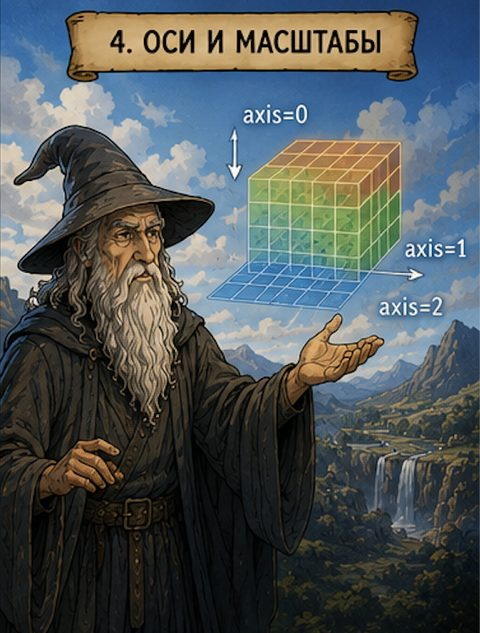</center>

Совет вождей анализирует потери пяти военачальников в четырёх походах.
Каждая строка соответствует военачальнику, каждый столбец — отдельному походу.
Чем меньше значение, тем успешнее прошёл бой.

1. Сформируйте матрицу размера **5×4** со случайными целыми значениями от 1 до 10 (`rng`). Строки — военачальники, столбцы — походы. **(2 балла)**
2. Для каждого похода вычислите средние потери среди всех военачальников. Затем для каждого военачальника вычислите его средние потери во всех походах. Выведите оба результата. **(4 балла)**
3. Определите: поход с наименьшими средними потерями; военачальника с наименьшими средними потерями; военачальника с наибольшим разбросом потерь между походами. **(3 балла)**
4. Для каждого похода определите военачальника, понёсшего наибольшие потери. Выведите номера походов и соответствующие номера военачальников. **(2 балла)**
5. Выполните стандартизацию потерь **отдельно для каждого военачальника**: для каждой строки вычтите средние потери этого военачальника и разделите результат на его стандартное отклонение. Используйте broadcasting и не применяйте циклы. Выведите стандартизированную матрицу. **(4 балла)**
6. Ответьте (в отдельной markdown-ячейке под кодом), кратко, двумя парами предложений:
   - Какой формы были исходные массивы в п.5 (среднее, std, сама матрица) и почему broadcasting сработал без явного приведения форм?
   - Почему среднее каждой строки после стандартизации близко к 0? **(4 балла)**


In [7]:
def council_of_chiefs():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    #1
    data = rng.integers(1, 11, size=(5,4))
    #2
    avg_by_collumns = np.mean(data, axis = 0) # средние потери военачальников для каждого похода
    avg_by_rows = np.mean(data, axis = 1) # для каждого началника средние потери во всех его походах
    print(avg_by_collumns)
    print(avg_by_rows)
    #3
    # Поход с наименьшими средними потерями
    np.argmin(avg_by_collumns) +1
    # Военачальник с наименьшими средними потерями
    np.argmin(avg_by_rows) + 1 
    # Военачальник с наибольшим разбросом потерь между походами
    np.argmax((np.max(data, axis=1) - np.argmin(data, axis=1))) + 1
    #4
    print(np.argmax(data, axis = 0))
    #5
    print((data -np.mean(data, axis=1, keepdims=True))/(np.std(data, axis=1, keepdims=True)))
    
    
    

council_of_chiefs()

[7.  4.8 5.4 7.2]
[6.25 5.25 6.25 5.25 7.5 ]
[4 0 0 2]
[[-1.52127766  0.50709255  1.18321596 -0.16903085]
 [ 0.39056673  0.39056673 -1.69245584  0.91132238]
 [-0.10050378 -1.30654916 -0.10050378  1.50755672]
 [ 1.6464639  -0.5488213  -0.10976426 -0.98787834]
 [ 0.96225045 -1.34715063 -0.57735027  0.96225045]]


**Ваш ответ:** _(формы массивов и почему broadcasting сработал; почему среднее по строке после стандартизации ~0)_


## Квест 5. Уникальное и порядок: Дозорный отряд (19 баллов)

<center>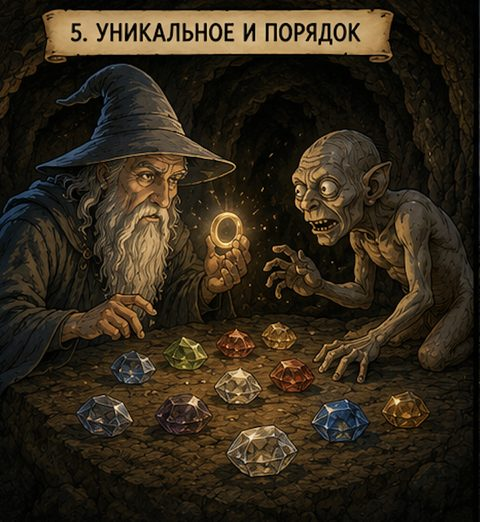</center>

Среди дозорных, посланных в дозор дважды, прячется один разведчик-невидимка.

1. Сформируйте массив из **25** случайных целых чисел от 1 до 50 (`rng`). Добавьте к нему первые 10 элементов этого же массива, после чего перемешайте (`rng.shuffle`). Получится массив длины **35** с повторами. **(3 балла)**
2. Найдите пять самых больших значений массива и их исходные позиции — средствами NumPy, без `sorted()` и ручной сортировки. **(4 балла)**
3. Определите все значения, которые встречаются в массиве ровно один раз. Выведите найденные значения и их количество. **(4 балла)**
4. Постройте таблицу вида "значение → количество повторений" **для всех уникальных значений массива** (не только для встретившихся один раз) и отсортируйте её по убыванию частоты. Выведите 5 самых частых значений вместе с их количеством. **(4 балла)**
5. Среди значений, встретившихся ровно один раз (п.3), найдите наибольшее чётное число — это разведчик-невидимка. Если подходящих значений нет, выведите соответствующее сообщение. **(4 балла)**


In [8]:
def find_the_scout():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
   #1
    massive = rng.integers(1, 51, size=25)
    massive = np.concatenate([massive, massive[:10]])
    rng.shuffle(massive)
    
    #2
    five_max_positions = np.argsort(massive)[-1:-6:-1]
    five_max_values = massive[five_max_positions]
    print(five_max_positions)
    print(five_max_values)
    #3
    values, counts = np.unique(massive, return_counts=True)
    count_one_time = values[counts == 1]
    lengh_count_one = len(count_one_time)
    print(lengh_count_one)
    #4
    values, counts = np.unique(massive, return_counts=True)
    table = np.vstack([values, counts])

    print(table[:,np.argsort(counts)[::-1]])
    
    #5
    find_number = count_one_time[count_one_time % 2 == 0]
    if len(find_number) > 1:
        print(find_number[np.argmax(find_number)])
    else:
        print(f"Разведчика-невидимки нет(")
        

    
find_the_scout()

[ 2 23  1  5  4]
[50 50 46 45 44]
10
[[ 9 34 27 29 28 25 50 38 33 30 46 41 44 22 17 16 45  6]
 [ 5  4  4  3  3  2  2  2  1  1  1  1  1  1  1  1  1  1]]
46


## Квест 6. Сила векторизации: NumPy vs чистый Python (23 балла)

<center>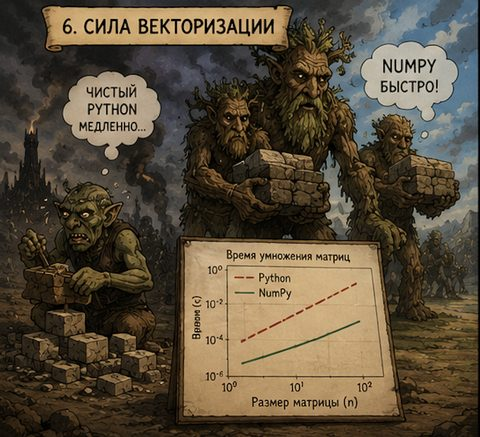</center>

*`time.perf_counter()` возвращает текущий момент времени в секундах.*

Сравните производительность умножения матриц через NumPy и через чистые списки Python.

1. Реализуйте функцию, которая с помощью `rng` формирует матрицу n×n из случайных целых чисел от 1 до 50 в виде вложенного списка Python. **(1 балл)**
2. Реализуйте функцию умножения двух матриц, заданных вложенными списками Python (без NumPy внутри). **(4 балла)**
3. Для размеров `n = 2, 5, 10, 20, 40, 60, 80, 100`: сформируйте матрицы `A` и `B` (используя ту же пару списков для обеих реализаций), выполните умножение **5 раз подряд** каждым способом и возьмите **медиану** времени выполнения (одно измерение — довольно шумная оценка). **(6 баллов)**

   *Почему так: время одного запуска сильно скачет от фоновой нагрузки системы; несколько повторов и медиана дают куда более честную оценку, чем единичный замер.*

4. Для одного выбранного размера сравните результаты двух реализаций и выведите, совпадают ли они с допустимой погрешностью. **(2 балла)**
5. Выведите таблицу: размер матрицы и медианное время выполнения каждой реализации. **(3 балла)**
6. Постройте график зависимости времени выполнения от размера матрицы — обе реализации на одном графике разными линиями. **(5 баллов)**
7. Ответьте (в отдельной markdown-ячейке под кодом): почему на маленьких матрицах (например, n=2 или n=5) преимущество NumPy может быть не таким впечатляющим — или вовсе не заметным? **(2 балла)**


True
Time without numpy: 1.7499551177024841e-06  	| Time with numpy: 1.2081582099199295e-06
True
Time without numpy: 9.333016350865364e-06  	| Time with numpy: 1.0409858077764511e-06
True
Time without numpy: 5.641602911055088e-05  	| Time with numpy: 1.250067725777626e-06
True
Time without numpy: 0.00040879216976463795  	| Time with numpy: 3.916909918189049e-06
True
Time without numpy: 0.0031130420975387096  	| Time with numpy: 2.8749927878379822e-05
True
Time without numpy: 0.010458791861310601  	| Time with numpy: 9.287497960031033e-05
True
Time without numpy: 0.025577833876013756  	| Time with numpy: 0.00023679202422499657
True
Time without numpy: 0.04790879203937948  	| Time with numpy: 0.00036037503741681576
     Time without numpy  Time with numpy
2              0.000002         0.000001
5              0.000009         0.000001
10             0.000056         0.000001
20             0.000409         0.000004
40             0.003113         0.000029
60             0.010459        

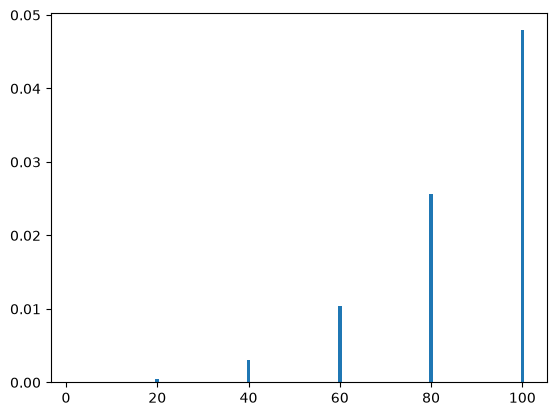

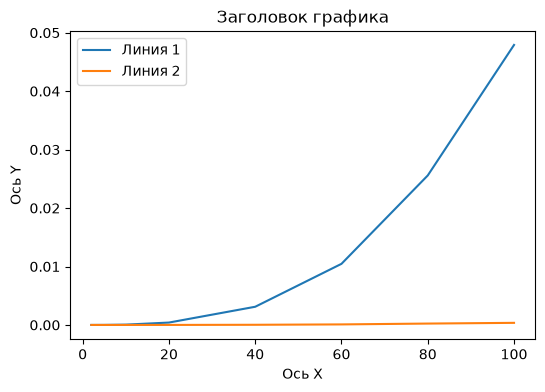

In [9]:
import time
import matplotlib.pyplot as plt
import pandas as pd
def random_matrix_as_list(n):
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    matrix_as_list = [[rng.integers(1, 51) for j in range(n)] for i in range(n)]
    return matrix_as_list

def matmul_python(a, b):
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    matrix_mat = []
    for i in range(len(a)):
        matrix_row = []
        k = 0
        while k != len(b):
            elem = 0 
            for j in range(len(b)):
                elem += a[i][j] * b[j][k]
            k += 1
            matrix_row.append(elem)
        matrix_mat.append(matrix_row)
    return matrix_mat

def numpy_vs_python_battle():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    ...
    
numbers = [2, 5, 10, 20, 40, 60, 80, 100]
dictionary = {}
for n in numbers:
    time_without_numpy = []
    time_with_numpy = []
    A = [list(map(int, sp)) for sp in random_matrix_as_list(n)]
    B = [list(map(int, sp)) for sp in random_matrix_as_list(n)]
    A_for_np = np.array(A)
    B_for_np = np.array(B)
    for i in range(5):
        start_time_without_numpy = time.perf_counter()
        C1 = matmul_python(A, B)
        end_time_without_numpy = time.perf_counter()
    
        start_time_with_numpy = time.perf_counter()
        C2 = A_for_np @ B_for_np
        end_time_with_numpy = time.perf_counter()
        
        w_time_without_numpy = end_time_without_numpy - start_time_without_numpy
        w_time_with_numpy = end_time_with_numpy - start_time_with_numpy
    
        time_without_numpy.append(w_time_without_numpy)
        time_with_numpy.append(w_time_with_numpy)
    print(f"{np.allclose(C1, C2)}")
    time_without_numpy.sort()
    median_time_without_numpy = time_without_numpy[2]
    time_with_numpy.sort()
    median_time_with_numpy = time_with_numpy[2]
    dictionary[n] = [median_time_without_numpy, median_time_with_numpy]

    print(f"Time without numpy: {median_time_without_numpy}  \t| Time with numpy: {median_time_with_numpy}")
df = pd.DataFrame(dictionary, index=['Time without numpy', 'Time with numpy']).T
df.head()
print(df)
numpy_vs_python_battle()

plt.bar(df.index, df['Time without numpy'])



fig, ax = plt.subplots(figsize=(6, 4))

# Рисуем данные на конкретном графике 'ax'
ax.plot(df.index, df['Time without numpy'], label='Линия 1')
ax.plot(df.index, df['Time with numpy'], label='Линия 2')
ax.set_title('Заголовок графика')
ax.set_xlabel('Ось X')
ax.set_ylabel('Ось Y')
ax.legend()

plt.show()

**Ваш ответ:** _(почему на маленьких матрицах преимущество numpy может быть незаметным)_


## Квест 7. Палантир видений (10 баллов)

<center>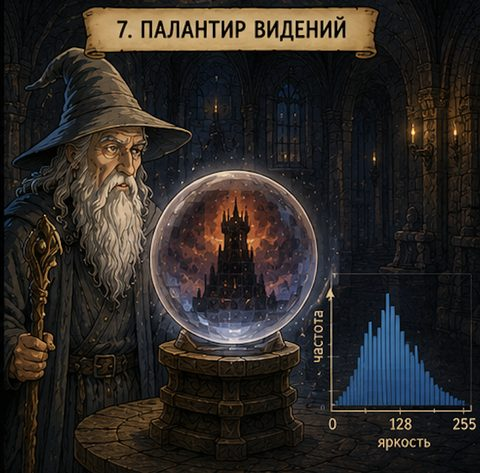</center>

*Используйте ИИ как верный спутник по теории работы numpy с изображениями - но в этой задаче вам хватит знаний занятий.*

Палантир — видящий камень Средиземья. В нём изображение представлено числовым массивом: каждая точка содержит значения трёх цветовых каналов — красного, зелёного и синего.

> - `np.meshgrid(np.arange(n), np.arange(n))` даёт две матрицы, `x` и `y`, координату каждого пикселя — удобно для узора через расстояние до центра, волны и т.п.
> - `np.clip(arr, a, b)` ограничивает значения в массиве диапазоном.

1. Сформируйте цветное изображение 120×120 пикселей (`rng`), три канала, значения 0–255. Пусть цвет каждого пикселя зависит от его координат x и y — например, от расстояния до центра, синуса/косинуса, диагонали или радиальных полос. Случайные значения можно добавить лишь слегка, чтобы изображение не выглядело полностью искусственным. **(2 балла)**
2. Получите одноканальную (яркостную) версию изображения без циклов, используя разные веса цветовых каналов - найдите в Интернете, какие обычно веса используют относительно восприятия яркости человеком. **(2 балла)**
3. Выделите центральную область 60×60 пикселей. **(1 балл)**
4. Создайте зеркальную версию изображения по горизонтали. **(1 балл)**
5. Увеличьте яркость изображения на 40 единиц, не выходя за допустимые границы. Яркость пикселя — это числовое значение в каналах RGB. Увеличить яркость на 40 означает прибавить 40 к каждому из трёх каналов каждого пикселя. Без циклов. **(2 балла)**
6. Отобразите исходное изображение и все преобразованные версии. Постройте распределение яркости для одноканального изображения. **(2 балла)**


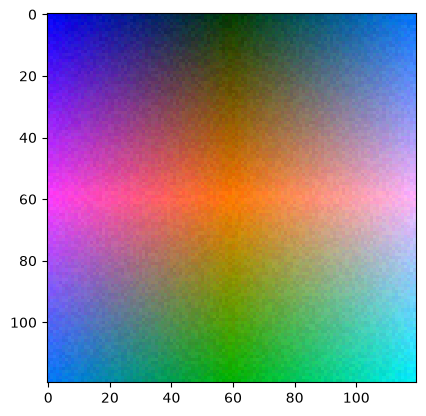

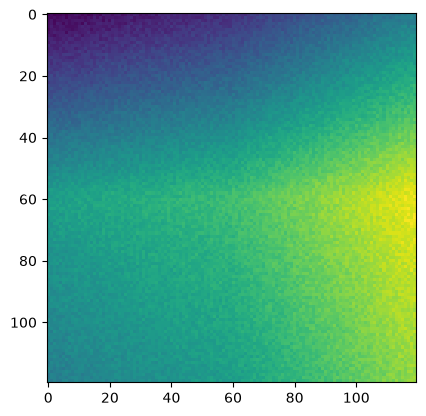

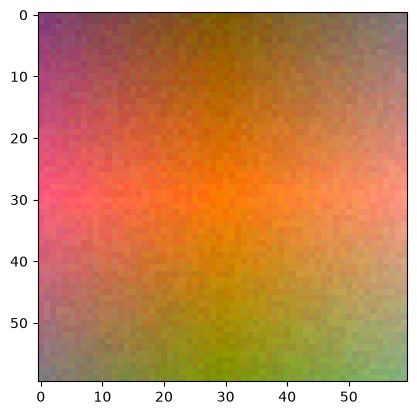

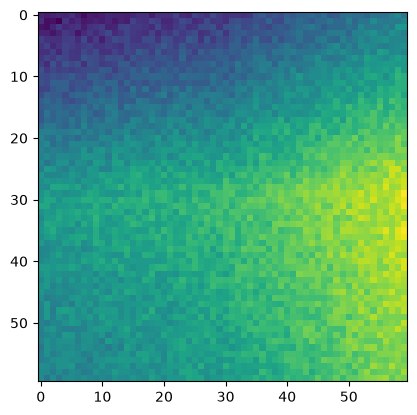

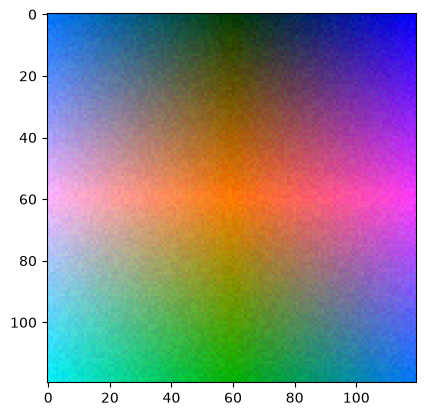

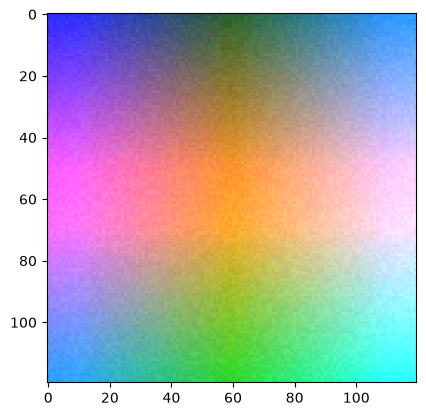

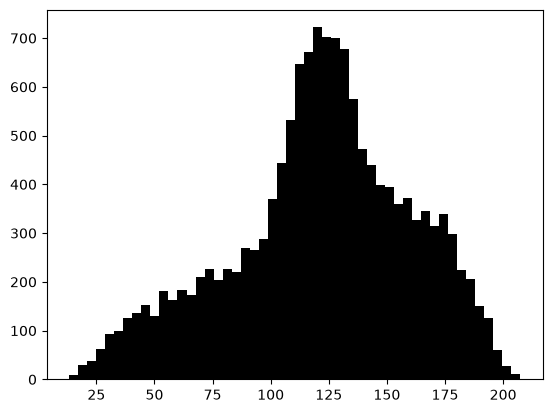

In [10]:
def look_into_the_palantir():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    X, Y = np.meshgrid(np.arange(120), np.arange(120))
    
    massive_pix = np.zeros((120,120,3))
    
    color_red = 255 - np.abs(Y-59.5)*4.25
    color_blue = np.abs(X-59.5)*4.25
    Z = X+Y
    color_green = Z 
    whight_sound = rng.integers(-9,10, size=(120,120,3))
    stack_colors = np.stack([color_red, color_green, color_blue], axis=2) + whight_sound
    
    massive_pix = np.clip(stack_colors, 0, 255).astype(np.uint8)
    
    plt.imshow(massive_pix)
    plt.show()
    #2
    one_chanel_of_massive = 0.2627 * massive_pix[:,:, 0] + 0.6780* massive_pix[:,:, 1] + 0.0593*massive_pix[:,:, 2]
    plt.imshow(np.clip(one_chanel_of_massive, 0, 255).astype(np.uint8))
    plt.show()
    #3
    central_area_for_massive_pix = massive_pix[120//2-30:120//2+30, 120//2-30:120//2+30, :]
    plt.imshow(central_area_for_massive_pix)
    plt.show()
    central_area_for_one_chanel_of_massive = one_chanel_of_massive[120//2-30:120//2+30, 120//2-30:120//2+30]
    plt.imshow(np.clip(central_area_for_one_chanel_of_massive, 0, 255).astype(np.uint8))
    plt.show()
    #4
    
    mirror_version = massive_pix[:, ::-1, :]
    plt.imshow(mirror_version)
    plt.show()
    #4 
    
    plt.imshow(np.clip(massive_pix.astype(float) + 40, 0, 255).astype(np.uint8))
    plt.show()
    #5
    plt.hist(one_chanel_of_massive.ravel(), bins=50, color='black')

look_into_the_palantir()

**Ваш ответ:** _(в каком диапазоне яркости сосредоточено больше всего пикселей и почему, на ваш взгляд, получилось именно так)_


## Квест 8. Три летописи (10 баллов)


Три летописца независимо записали результаты трёх испытаний — по 6 чисел каждый.

1. Сгенерируйте три отдельных массива по **6** случайных целых чисел от 0 до 20 каждый (`rng.integers`). **(2 балла)**
2. Объедините все три в **один длинный одномерный массив** длины 18. **(2 балла)**
3. Объедините их **по строкам** — так, чтобы получилась матрица 3×6 (строка — это летописец). **(2 балла)**
4. Объедините их **по столбцам** — так, чтобы получилась матрица 6×3 (столбец — это летописец). **(2 балла)**
5. Ответьте (в отдельной markdown-ячейке под кодом): в чём разница между `np.concatenate` и `np.stack`? Почему нельзя получить результат пункта 4 простым вызовом `np.hstack` на исходных трёх одномерных массивах? **(2 балла)**


In [11]:
def three_chronicles():
    '''
    Допишите docstring сами: 1-2 предложения о том, что делает эта функция.
    '''
    # Твой код здесь
    
    first_massive = rng.integers(0, 21, size=6)
    second_massive = rng.integers(0, 21, size=6)
    third_massive = rng.integers(0, 21, size=6)
    
    concatenate_massives = np.concatenate([first_massive, second_massive, third_massive])
    
    print(concatenate_massives.shape)
    
    #3
    
    print(np.vstack([first_massive, second_massive, third_massive]).shape)
    #4
    print(np.vstack([first_massive, second_massive, third_massive]).T.shape)
    
    
    
    
    
    
    

three_chronicles()

(18,)
(3, 6)
(6, 3)


**Ваш ответ:** _(разница между concatenate и stack, и почему hstack на 1D-массивах не даёт матрицу 6×3)_
